<center><h1>Трехмерные сверточные слои

In [16]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import numpy as np
import h5py
from matplotlib.pyplot import cm
import matplotlib.pyplot as plt

In [8]:
with h5py.File('full_dataset_vectors.h5', 'r') as dataset:
    X_train = dataset['X_train'][:]
    X_test = dataset['X_test'][:]
    y_train = dataset['y_train'][:]
    y_test = dataset['y_test'][:]

In [9]:
X_train.shape

(10000, 4096)

10000 изображений, заданных векторами в 4096 значений

In [13]:
xtrain = np.ndarray((X_train.shape[0], 4096, 3))
xtest = np.ndarray((X_test.shape[0], 4096, 3))


def add_rgb_dimension(array):
    scaler_map = cm.ScalarMappable(cmap='Oranges')
    array = scaler_map.to_rgba(array)[:, :-1]
    return array

for i in range(X_train.shape[0]):
    xtrain[i] = add_rgb_dimension(X_train[i])

for i in range(X_test.shape[0]):
    xtest[i] = add_rgb_dimension(X_test[i])

# Добавили цвета
# Переконвертируем в 4D + 1 пространство

xtrain = xtrain.reshape(X_train.shape[0], 16, 16, 16, 3)
xtest = xtest.reshape(X_test.shape[0], 16, 16, 16, 3)

xtrain = xtrain.transpose(0, 4, 1, 2, 3)
xtest = xtest.transpose(0, 4, 1, 2, 3)


In [15]:
print(xtrain.shape)
print(y_train.shape)

(10000, 3, 16, 16, 16)
(10000,)


In [18]:
class MNIST3D(Dataset):
    def __init__(self, x, y):
        self.x = x
        self.y = y
        self.transform = transforms.ToTensor()
        # Нативно используем переход в тензор
    
    # Ниже две обязательных функции
    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, idx):
        x = torch.from_numpy(self.x[idx]).float()
        y = self.y[idx]
        return x, y

In [32]:
class Conv3DNet(nn.Module):
    def __init__(self):
        super(Conv3DNet, self).__init__()
        self.conv1 = nn.Conv3d(in_channels=3, out_channels=16, kernel_size=3,
                               stride=1, padding=1)
        self.conv2 = nn.Conv3d(in_channels=16, out_channels=32, kernel_size=3,
                               stride=1, padding=1)
        self.conv3 = nn.Conv3d(in_channels=32, out_channels=64, kernel_size=3,
                               stride=1, padding=1)
        self.pool = nn.MaxPool3d(kernel_size=2, stride=2)
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(in_features=512, out_features=120)
        self.linear2 = nn.Linear(in_features=120, out_features=10)
        self.activation = nn.ReLU()
        self.layers = [self.conv1, self.activation, self.pool,
                       self.conv2, self.activation, self.pool,
                       self.conv3, self.activation, self.pool,
                       self.flatten, self.linear1, self.activation,
                       self.linear2]
        
    def forward(self, x):
        self.feature_maps = []
        for layer in self.layers:
            x = layer(x)
            if isinstance(layer, nn.Conv3d):
                self.feature_maps.append(x.detach())
        return x

In [33]:
train_dataset = MNIST3D(xtrain, y_train)
test_dataset = MNIST3D(xtest, y_test)

In [34]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [35]:
device = 'cuda' if torch.cuda.is_available else 'cpu'
device

'cuda'

In [36]:
model = Conv3DNet().to(device)
model

Conv3DNet(
  (conv1): Conv3d(3, 16, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (conv2): Conv3d(16, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (conv3): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (pool): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=512, out_features=120, bias=True)
  (linear2): Linear(in_features=120, out_features=10, bias=True)
  (activation): ReLU()
)

In [37]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [38]:
print(sum(p.numel() for p in model.parameters()))

133298


In [39]:
EPOCHS = 50

for epoch in range(EPOCHS):
    model.train()
    train_loss, test_loss = [], []
    print('Starting epoch: ', epoch + 1)
    for data, targets in train_loader:
        data, targets = data.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        train_loss.append(loss.item())

    model.eval()
    with torch.inference_mode():
        total_correct = 0
        total_samples = len(test_loader.dataset)
        for data, targets in test_loader:
            data, targets = data.to(device), targets.to(device)
            outputs = model(data)
            loss = criterion(outputs, targets)
            test_loss.append(loss.item())
            classes = torch.argmax(outputs, -1)
            correct = (classes == targets).sum().item()
            total_correct += correct
    print(f'Epoch {epoch + 1} train_loss: {np.mean(train_loss)} test_loss: {np.mean(test_loss)} accuracy: {100 * total_correct / total_samples}%')

Starting epoch:  1
Epoch 1 train_loss: 2.228146141052246 test_loss: 1.927822422027588 accuracy: 33.95%
Starting epoch:  2
Epoch 2 train_loss: 1.8053733200073243 test_loss: 1.6077721529006959 accuracy: 44.65%
Starting epoch:  3
Epoch 3 train_loss: 1.5943162628173828 test_loss: 1.4714211330413818 accuracy: 50.45%
Starting epoch:  4
Epoch 4 train_loss: 1.4675960596084594 test_loss: 1.352760344028473 accuracy: 53.8%
Starting epoch:  5
Epoch 5 train_loss: 1.373430928516388 test_loss: 1.3313539958000182 accuracy: 54.9%
Starting epoch:  6
Epoch 6 train_loss: 1.2963012948036194 test_loss: 1.2244164023399353 accuracy: 57.95%
Starting epoch:  7
Epoch 7 train_loss: 1.2356698288917543 test_loss: 1.185191180229187 accuracy: 58.8%
Starting epoch:  8
Epoch 8 train_loss: 1.1867037282466888 test_loss: 1.140073709487915 accuracy: 60.55%
Starting epoch:  9
Epoch 9 train_loss: 1.1393885834693909 test_loss: 1.1086993210315705 accuracy: 60.9%
Starting epoch:  10
Epoch 10 train_loss: 1.106035704612732 test_l

In [58]:
def vizualize_conv3d_feature_maps(feature_maps, slice_idx_override=None):
    for layer_idx, feature_map in enumerate(feature_maps):
        num_filters = feature_map.shape[1]
        print(f'Layer {layer_idx + 1}')
        if slice_idx_override is None:
            slice_idx = feature_map.shape[2] // 2
        else:
            slice_idx = slice_idx_override
        if slice_idx < 0 or slice_idx >= feature_map.shape[2]:
            continue
        num_cols = 8
        num_rows = (min(num_filters, 64) + num_cols - 1)
        fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, 2 * num_rows))
        axes = axes.flatten()
        for i in range(min(num_filters, 64)):
            ax = axes[i]
            feature_slice = feature_map[0, i, slice_idx, :, :].cpu().numpy()
            ax.imshow(feature_slice, cmap='gray')
            ax.axis('off')
            ax.set_title(f'Filter {i + 1}')

        for i in range(min(num_filters, 64), num_rows * num_cols):
            axes[i].axis('off')
        
        plt.tight_layout()
        plt.show()

Layer 1


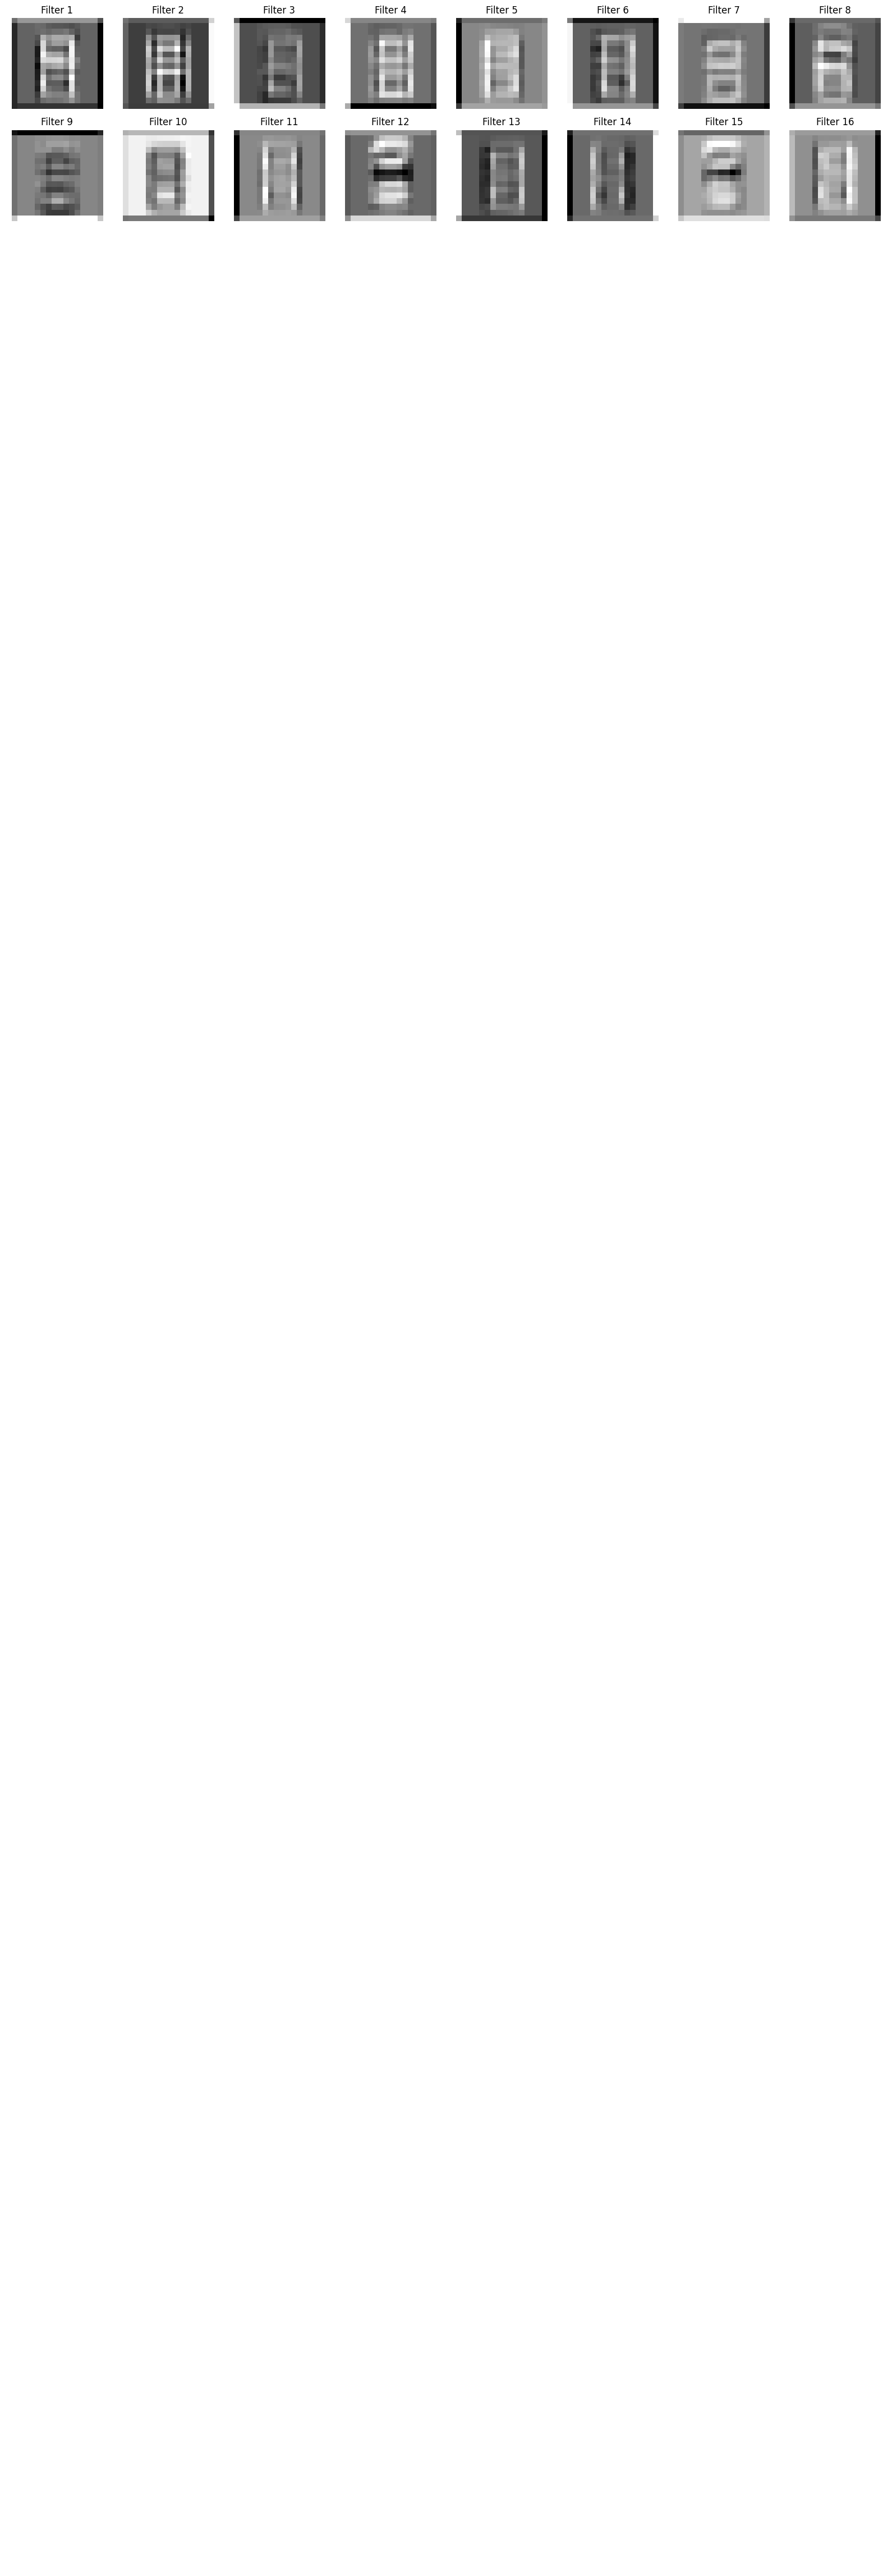

Layer 2


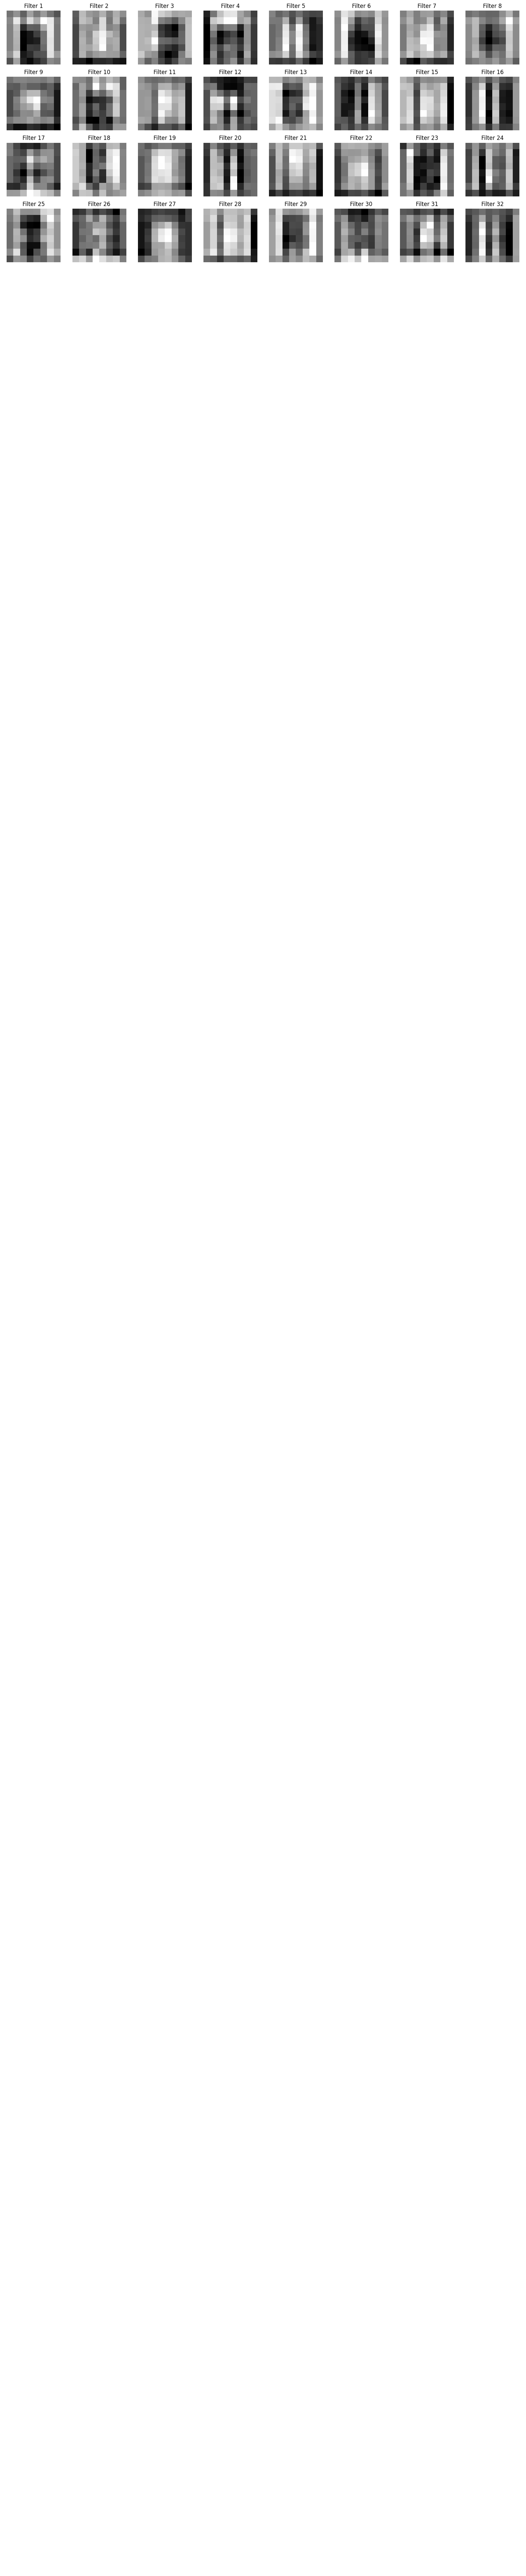

Layer 3




In [59]:
vizualize_conv3d_feature_maps(model.feature_maps)

In [62]:
def inference(model, test_loader):
    model.eval()
    dataiter = iter(test_loader)
    data, targets = next(dataiter)
    data, targets = data.to(device), targets.to(device)
    outputs = model(data)
    outputs = torch.argmax(outputs, -1)
    return outputs, targets

In [63]:
outputs, targets = inference(model, test_loader)
print(outputs)
print()
print(targets)

tensor([7, 7, 2, 7, 1, 1, 0, 0, 4, 4, 1, 1, 4, 7, 4, 9], device='cuda:0')

tensor([7, 7, 2, 2, 1, 1, 0, 0, 4, 4, 1, 1, 4, 4, 9, 9], device='cuda:0')


Используется для определения размеров. Проблема: мало данных